In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [5]:
print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"Numpy version: {np.__version__}")

Libraries imported successfully!
Pandas version: 2.2.3
Numpy version: 2.1.3


In [6]:
print("Loading data...")
train = pd.read_csv(r"C:\Users\Shivam Gupta\Coding\smart-supply-chain\data\raw\train.csv", low_memory=False)
store = pd.read_csv(r"C:\Users\Shivam Gupta\Coding\smart-supply-chain\data\raw\store.csv")

Loading data...


In [7]:
print(f"Data loaded successfully!")
print(f"Train shape: {train.shape}")
print(f"Store shape: {store.shape}")

Data loaded successfully!
Train shape: (1017209, 9)
Store shape: (1115, 10)


In [8]:
print("="*80)
print("TRAIN DATA - FIRST 10 ROWS")
print("="*80)
display(train.head(10))

TRAIN DATA - FIRST 10 ROWS


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
5,6,5,2015-07-31,5651,589,1,1,0,1
6,7,5,2015-07-31,15344,1414,1,1,0,1
7,8,5,2015-07-31,8492,833,1,1,0,1
8,9,5,2015-07-31,8565,687,1,1,0,1
9,10,5,2015-07-31,7185,681,1,1,0,1


In [9]:
print("="*80)
print("STORE DATA - FIRST 10 ROWS")
print("="*80)
display(store.head(10)) 

STORE DATA - FIRST 10 ROWS


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
5,6,a,a,310.0,12.0,2013.0,0,NaN,NaN,NaN
6,7,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
7,8,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
8,9,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
9,10,a,a,3160.0,9.0,2009.0,0,NaN,NaN,NaN


In [10]:
print("="*80)
print("TRAIN DATA INFORMATION")
print("="*80)
train.info()

TRAIN DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


In [11]:
print("="*80)
print("STORE DATA INFORMATION")
print("="*80)
store.info()

STORE DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [12]:
print("="*80)
print("TRAIN DATA - NUMERICAL SUMMARY")
print("="*80)
display(train.describe())

TRAIN DATA - NUMERICAL SUMMARY


,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


In [13]:
print("="*80)
print("STORE DATA - NUMERICAL SUMMARY")
print("="*80)
display(store.describe())

STORE DATA - NUMERICAL SUMMARY


,Store,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1115.00000,1112.000000,761.000000,761.000000,1115.000000,571.000000,571.000000
mean,558.00000,5404.901079,7.224704,2008.668857,0.512108,23.595447,2011.763573
std,322.01708,7663.174720,3.212348,6.195983,0.500078,14.141984,1.674935
min,1.00000,20.000000,1.000000,1900.000000,0.000000,1.000000,2009.000000
25%,279.50000,717.500000,4.000000,2006.000000,0.000000,13.000000,2011.000000
50%,558.00000,2325.000000,8.000000,2010.000000,1.000000,22.000000,2012.000000
75%,836.50000,6882.500000,10.000000,2013.000000,1.000000,37.000000,2013.000000
max,1115.00000,75860.000000,12.000000,2015.000000,1.000000,50.000000,2015.000000


In [14]:
print("="*80)
print("TRAIN DATA - CATEGORICAL VARIABLES")
print("="*80)
for col in train.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(train[col].value_counts())

TRAIN DATA - CATEGORICAL VARIABLES

Date:
Date
2013-01-02    1115
2015-07-31    1115
2015-07-30    1115
2015-07-29    1115
2015-07-28    1115
              ... 
2014-12-28     935
2014-12-26     935
2014-12-25     935
2014-12-24     935
2014-12-23     935
Name: count, Length: 942, dtype: int64

StateHoliday:
StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: int64


In [15]:
print("="*80)
print("STORE DATA - CATEGORICAL VARIABLES")
print("="*80)
for col in store.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(store[col].value_counts())

STORE DATA - CATEGORICAL VARIABLES

StoreType:
StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64

Assortment:
Assortment
a    593
c    513
b      9
Name: count, dtype: int64

PromoInterval:
PromoInterval
Jan,Apr,Jul,Oct     335
Feb,May,Aug,Nov     130
Mar,Jun,Sept,Dec    106
Name: count, dtype: int64


In [16]:
print("="*80)
print("MISSING VALUES ANALYSIS")
print("="*80)

print("\n--- TRAIN DATA ---")
train_missing = train.isnull().sum()
train_missing_pct = (train.isnull().sum() / len(train)) * 100
missing_train = pd.DataFrame({
    'Missing_Count': train_missing,
    'Percentage': train_missing_pct
}).sort_values(by='Missing_Count', ascending=False)
print(missing_train[missing_train['Missing_Count'] > 0])

print("\n--- STORE DATA ---")
store_missing = store.isnull().sum()
store_missing_pct = (store.isnull().sum() / len(store)) * 100
missing_store = pd.DataFrame({
    'Missing_Count': store_missing,
    'Percentage': store_missing_pct
}).sort_values(by='Missing_Count', ascending=False)
print(missing_store[missing_store['Missing_Count'] > 0])

MISSING VALUES ANALYSIS

--- TRAIN DATA ---
Empty DataFrame
Columns: [Missing_Count, Percentage]
Index: []

--- STORE DATA ---
                           Missing_Count  Percentage
PromoInterval                        544   48.789238
Promo2SinceYear                      544   48.789238
Promo2SinceWeek                      544   48.789238
CompetitionOpenSinceYear             354   31.748879
CompetitionOpenSinceMonth            354   31.748879
CompetitionDistance                    3    0.269058


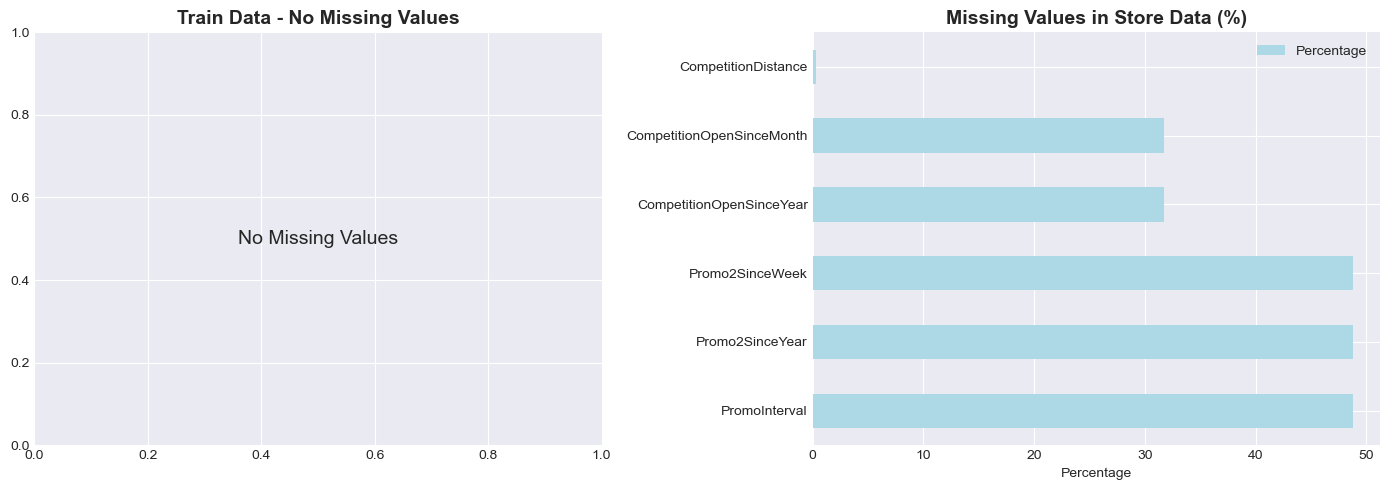

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if missing_train['Missing_Count'].sum() > 0:
    missing_train[missing_train['Missing_Count'] > 0].plot(
        kind='barh', y='Percentage', ax=axes[0], color='coral'
    )
    axes[0].set_title('Missing Values in Train Data (%)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Percentage')
else:
    axes[0].text(0.5, 0.5, 'No Missing Values', ha='center', va='center', fontsize=14)
    axes[0].set_title('Train Data - No Missing Values', fontsize=14, fontweight='bold')

if missing_store['Missing_Count'].sum() > 0:
    missing_store[missing_store['Missing_Count'] > 0].plot(
        kind='barh', y='Percentage', ax=axes[1], color='lightblue'
    )
    axes[1].set_title('Missing Values in Store Data (%)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Percentage')
else:
    axes[1].text(0.5, 0.5, 'No Missing Values', ha='center', va='center', fontsize=14)
    axes[1].set_title('Store Data - No Missing Values', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [18]:
print("="*80)
print("STORES THAT ARE ALWAYS CLOSED")
print("="*80)
always_closed = train.groupby('Store')['Open'].sum()
closed_stores = always_closed[always_closed == 0]
print(f"Number of stores always closed: {len(closed_stores)}")
if len(closed_stores) > 0:
    print(f"Store IDs: {list(closed_stores.index)}")

STORES THAT ARE ALWAYS CLOSED
Number of stores always closed: 0


In [19]:
df = train.merge(store, on='Store', how='left')
print(f"✅ Data merged successfully!")
print(f"Merged data shape: {df.shape}")
print(f"Columns: {list(df.columns)}")


✅ Data merged successfully!
Merged data shape: (1017209, 18)
Columns: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


In [20]:
print("="*80)
print("MERGED DATA SAMPLE")
print("="*80)
display(df.head(10))

MERGED DATA SAMPLE


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
5,6,5,2015-07-31,5651,589,1,1,0,1,a,a,310.0,12.0,2013.0,0,NaN,NaN,NaN
6,7,5,2015-07-31,15344,1414,1,1,0,1,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
7,8,5,2015-07-31,8492,833,1,1,0,1,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
8,9,5,2015-07-31,8565,687,1,1,0,1,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
9,10,5,2015-07-31,7185,681,1,1,0,1,a,a,3160.0,9.0,2009.0,0,NaN,NaN,NaN


In [21]:
# Convert to datetime (safe conversion)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Drop rows where 'Date' could not be parsed
df = df.dropna(subset=['Date'])

# Extract date components
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day

# Works in Jupyter for Pandas 1.x and 2.x+
df['WeekOfYear'] = df['Date'].dt.isocalendar()['week']

df['Quarter'] = df['Date'].dt.quarter
df['DayName'] = df['Date'].dt.day_name()
df['MonthName'] = df['Date'].dt.month_name()

# Safe printing in Jupyter (avoids .date() errors)
start_date = df['Date'].min().strftime('%Y-%m-%d')
end_date = df['Date'].max().strftime('%Y-%m-%d')
total_days = (df['Date'].max() - df['Date'].min()).days

print("Date features created!")
print(f"Date range: {start_date} to {end_date}")
print(f"Total days: {total_days} days")
print(f"Total years: {df['Year'].nunique()} years")


Date features created!
Date range: 2013-01-01 to 2015-07-31
Total days: 941 days
Total years: 3 years


In [22]:
display(df[['Date', 'Year', 'Month', 'Day', 'DayOfWeek', 'WeekOfYear', 'Quarter', 'DayName', 'MonthName']].head(10))


,Date,Year,Month,Day,DayOfWeek,WeekOfYear,Quarter,DayName,MonthName
0,2015-07-31,2015,7,31,5,31,3,Friday,July
1,2015-07-31,2015,7,31,5,31,3,Friday,July
2,2015-07-31,2015,7,31,5,31,3,Friday,July
3,2015-07-31,2015,7,31,5,31,3,Friday,July
4,2015-07-31,2015,7,31,5,31,3,Friday,July
5,2015-07-31,2015,7,31,5,31,3,Friday,July
6,2015-07-31,2015,7,31,5,31,3,Friday,July
7,2015-07-31,2015,7,31,5,31,3,Friday,July
8,2015-07-31,2015,7,31,5,31,3,Friday,July
9,2015-07-31,2015,7,31,5,31,3,Friday,July


In [23]:
# Overall statistics
print("="*80)
print("OVERALL BUSINESS STATISTICS")
print("="*80)
print(f"Total Stores: {df['Store'].nunique()}")
print(f"Total Records: {len(df):,}")
print(f"Date Range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Total Days: {df['Date'].nunique()} days")
print(f"\n--- SALES STATISTICS ---")
print(f"Total Sales: ${df['Sales'].sum():,.0f}")
print(f"Average Daily Sales per Store: ${df['Sales'].mean():,.2f}")
print(f"Median Daily Sales per Store: ${df['Sales'].median():,.2f}")
print(f"Max Daily Sales: ${df['Sales'].max():,.0f}")
print(f"Min Daily Sales: ${df['Sales'].min():,.0f}")
print(f"\n--- CUSTOMER STATISTICS ---")
print(f"Average Daily Customers per Store: {df['Customers'].mean():,.0f}")
print(f"Total Customers: {df['Customers'].sum():,}")

OVERALL BUSINESS STATISTICS
Total Stores: 1115
Total Records: 1,017,209
Date Range: 2013-01-01 to 2015-07-31
Total Days: 942 days

--- SALES STATISTICS ---
Total Sales: $5,873,180,623
Average Daily Sales per Store: $5,773.82
Median Daily Sales per Store: $5,744.00
Max Daily Sales: $41,551
Min Daily Sales: $0

--- CUSTOMER STATISTICS ---
Average Daily Customers per Store: 633
Total Customers: 644,041,755


In [24]:
# Sales when stores are open vs closed
print("="*80)
print("SALES: OPEN vs CLOSED STORES")
print("="*80)
open_sales = df.groupby('Open')['Sales'].agg(['count', 'sum', 'mean', 'median'])
display(open_sales)

# Filter only open stores for further analysis
df_open = df[df['Open'] == 1].copy()
print(f"\n Filtered to open stores only: {len(df_open):,} records")

SALES: OPEN vs CLOSED STORES


,count,sum,mean,median
Open,,,,
0,172817,0,0.000000,0.0
1,844392,5873180623,6955.514291,6369.0



 Filtered to open stores only: 844,392 records


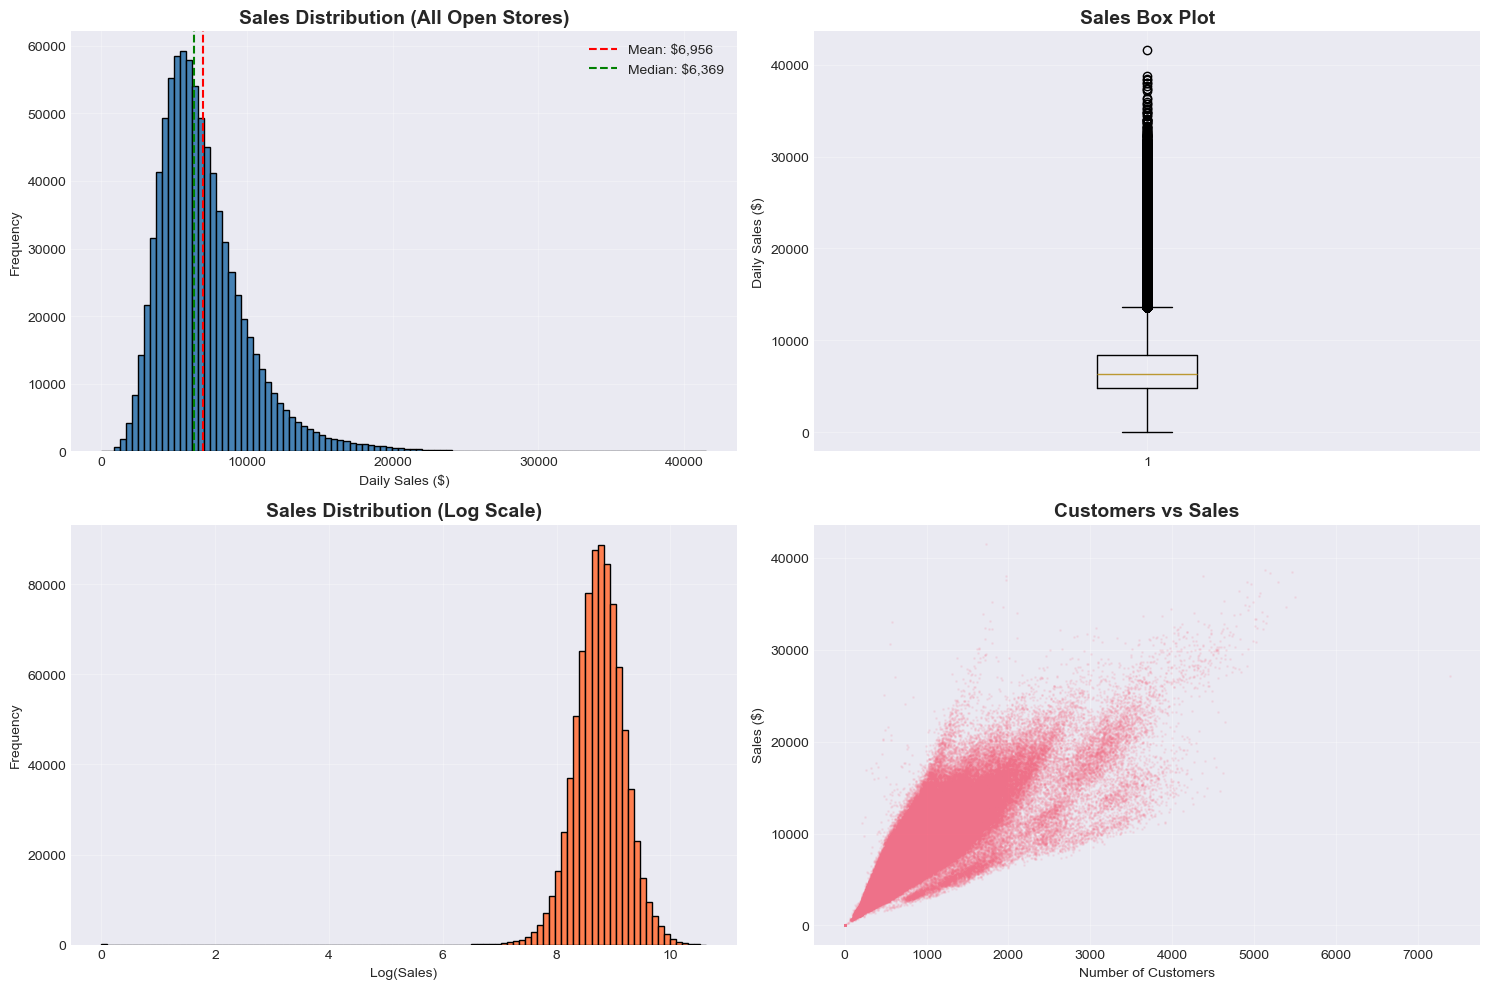

📊 Key Insights:
- Distribution is right-skewed (most days have moderate sales)
- Outliers exist (very high sales days - likely promotions/holidays)
- Strong correlation between customers and sales


In [25]:
# Sales distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Histogram
axes[0, 0].hist(df_open['Sales'], bins=100, edgecolor='black', color='steelblue')
axes[0, 0].set_title('Sales Distribution (All Open Stores)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Daily Sales ($)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].axvline(df_open['Sales'].mean(), color='red', linestyle='--', label=f"Mean: ${df_open['Sales'].mean():,.0f}")
axes[0, 0].axvline(df_open['Sales'].median(), color='green', linestyle='--', label=f"Median: ${df_open['Sales'].median():,.0f}")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Box plot
axes[0, 1].boxplot(df_open['Sales'], vert=True)
axes[0, 1].set_title('Sales Box Plot', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Daily Sales ($)')
axes[0, 1].grid(alpha=0.3)

# Log-scale histogram
axes[1, 0].hist(np.log1p(df_open['Sales']), bins=100, edgecolor='black', color='coral')
axes[1, 0].set_title('Sales Distribution (Log Scale)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Log(Sales)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(alpha=0.3)

# Customers vs Sales scatter
axes[1, 1].scatter(df_open['Customers'], df_open['Sales'], alpha=0.1, s=1)
axes[1, 1].set_title('Customers vs Sales', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Number of Customers')
axes[1, 1].set_ylabel('Sales ($)')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Key Insights:")
print(f"- Distribution is right-skewed (most days have moderate sales)")
print(f"- Outliers exist (very high sales days - likely promotions/holidays)")
print(f"- Strong correlation between customers and sales")

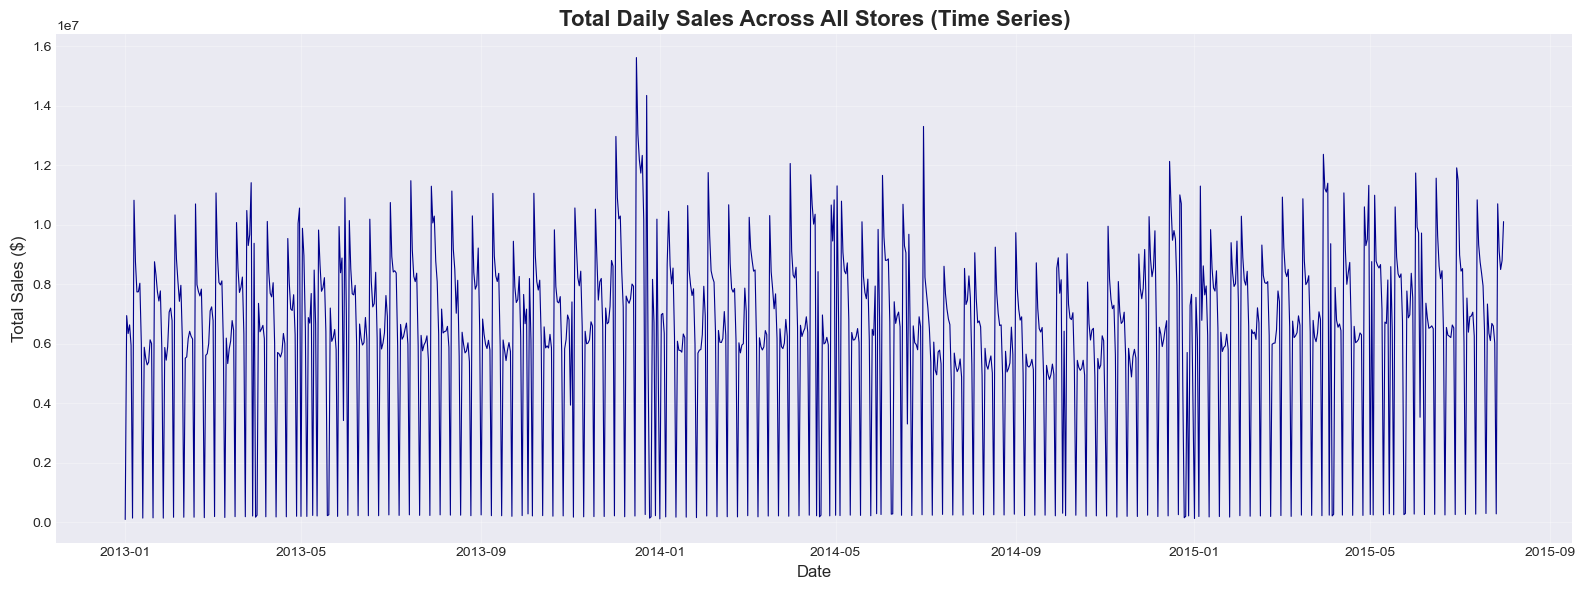

Observations:
- Clear periodic patterns (weekly cycles)
- Some periods of zero or very low sales (holidays, store closures)
- End-of-year spikes (December - Christmas shopping)


In [26]:
# Daily sales trend (aggregated across all stores)
daily_total = df_open.groupby('Date')['Sales'].sum().reset_index()

plt.figure(figsize=(16, 6))
plt.plot(daily_total['Date'], daily_total['Sales'], linewidth=0.8, color='darkblue')
plt.title('Total Daily Sales Across All Stores (Time Series)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Observations:")
print("- Clear periodic patterns (weekly cycles)")
print("- Some periods of zero or very low sales (holidays, store closures)")
print("- End-of-year spikes (December - Christmas shopping)")

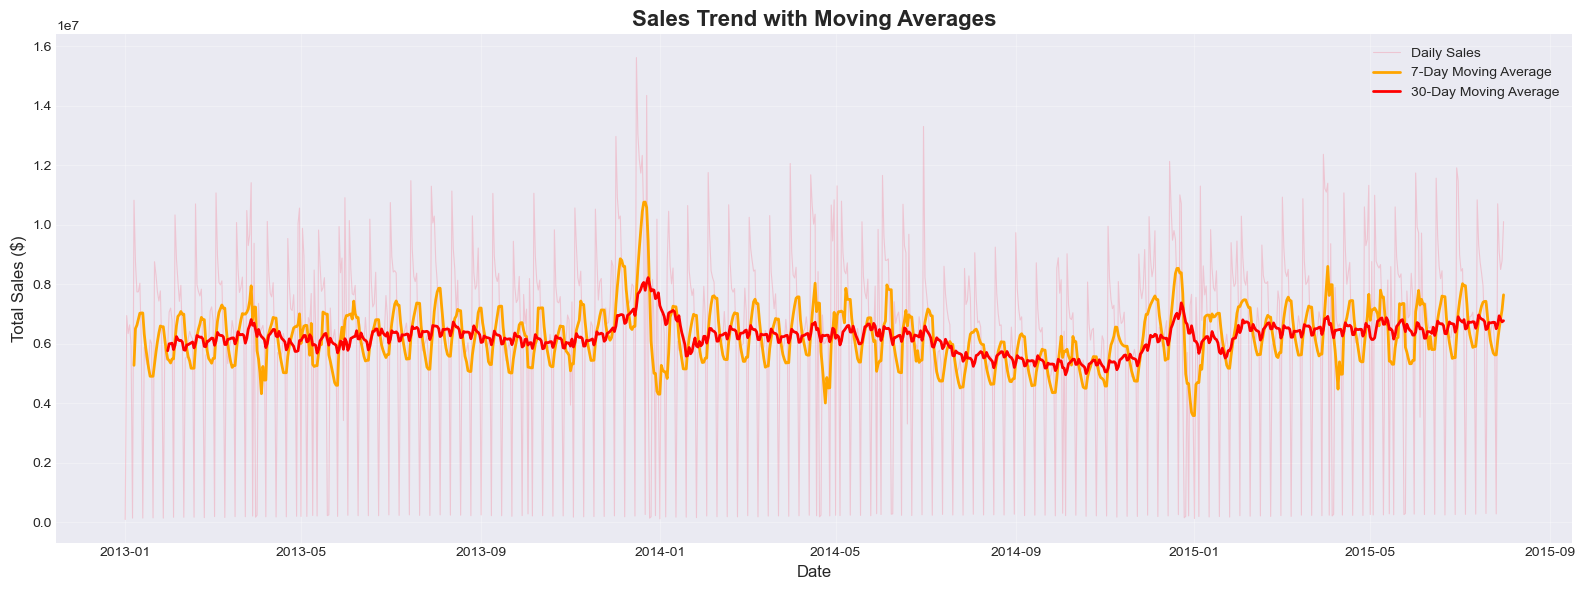

📊 Trend Analysis:
- Overall upward trend in sales over the years
- Strong seasonal patterns visible
- 30-day MA smooths out weekly volatility


In [27]:
# Moving averages to see trend
daily_total['MA_7'] = daily_total['Sales'].rolling(window=7).mean()
daily_total['MA_30'] = daily_total['Sales'].rolling(window=30).mean()

plt.figure(figsize=(16, 6))
plt.plot(daily_total['Date'], daily_total['Sales'], alpha=0.3, label='Daily Sales', linewidth=0.8)
plt.plot(daily_total['Date'], daily_total['MA_7'], label='7-Day Moving Average', linewidth=2, color='orange')
plt.plot(daily_total['Date'], daily_total['MA_30'], label='30-Day Moving Average', linewidth=2, color='red')
plt.title('Sales Trend with Moving Averages', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("📊 Trend Analysis:")
print("- Overall upward trend in sales over the years")
print("- Strong seasonal patterns visible")
print("- 30-day MA smooths out weekly volatility")

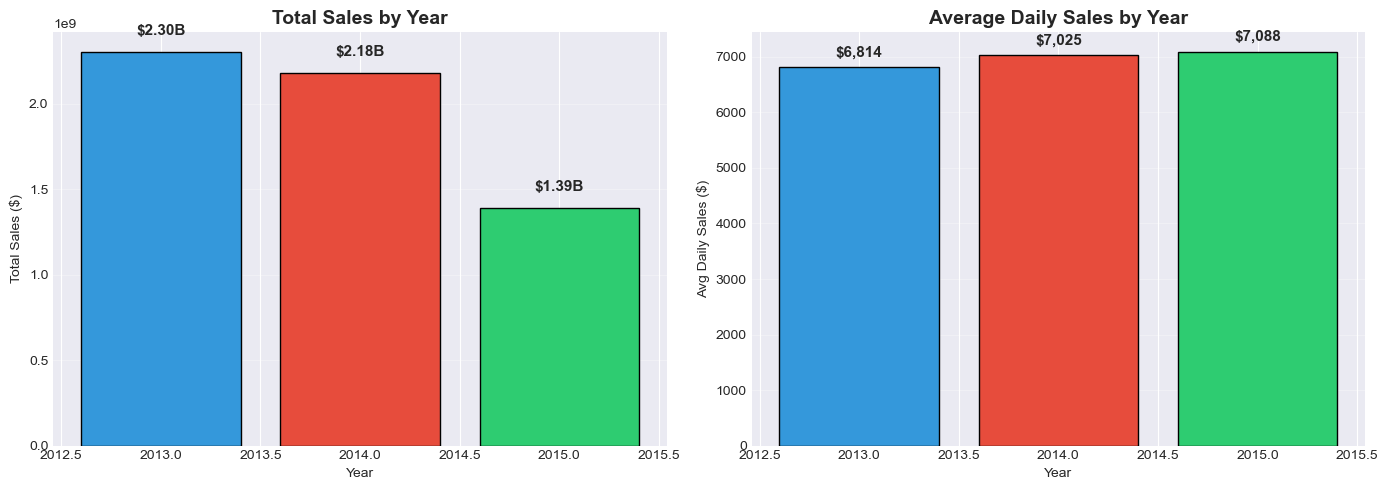

📊 Yearly Trends:


,Year,Total_Sales,Avg_Daily_Sales,Days
0,2013,2302876084,6814.392025,337943
1,2014,2180804896,7025.404201,310417
2,2015,1389499643,7088.126648,196032


In [28]:
# Sales by Year
yearly_sales = df_open.groupby('Year')['Sales'].agg(['sum', 'mean', 'count']).reset_index()
yearly_sales.columns = ['Year', 'Total_Sales', 'Avg_Daily_Sales', 'Days']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Total sales by year
axes[0].bar(yearly_sales['Year'], yearly_sales['Total_Sales'], color=['#3498db', '#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title('Total Sales by Year', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Total Sales ($)')
axes[0].grid(axis='y', alpha=0.3)
for i, row in yearly_sales.iterrows():
    axes[0].text(row['Year'], row['Total_Sales'] + 1e8, f"${row['Total_Sales']/1e9:.2f}B", 
                ha='center', fontsize=11, fontweight='bold')

# Average daily sales by year
axes[1].bar(yearly_sales['Year'], yearly_sales['Avg_Daily_Sales'], color=['#3498db', '#e74c3c', '#2ecc71'], edgecolor='black')
axes[1].set_title('Average Daily Sales by Year', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Avg Daily Sales ($)')
axes[1].grid(axis='y', alpha=0.3)
for i, row in yearly_sales.iterrows():
    axes[1].text(row['Year'], row['Avg_Daily_Sales'] + 200, f"${row['Avg_Daily_Sales']:,.0f}", 
                ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("📊 Yearly Trends:")
display(yearly_sales)

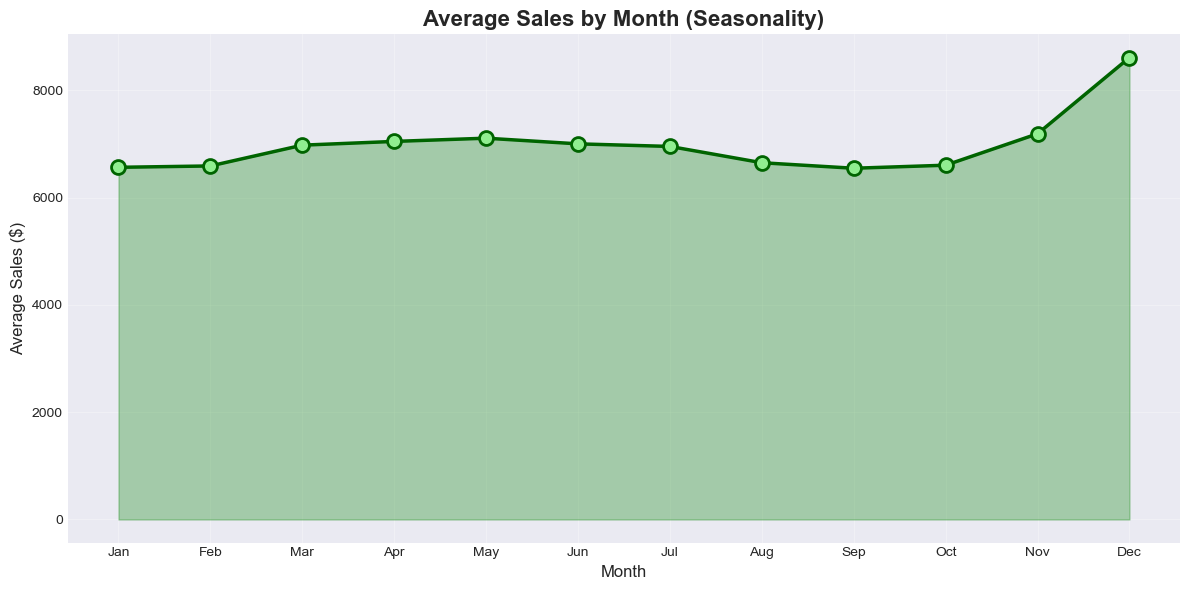

📊 Monthly Seasonality:
- Best month: Month 12 with $8,609 avg sales
- Worst month: Month 9 with $6,546 avg sales
- Seasonal variation: 31.5% difference


In [29]:
# Sales by Month
monthly_sales = df_open.groupby('Month')['Sales'].mean().reset_index()

plt.figure(figsize=(12, 6))
plt.plot(monthly_sales['Month'], monthly_sales['Sales'], marker='o', linewidth=2.5, 
         markersize=10, color='darkgreen', markerfacecolor='lightgreen', markeredgewidth=2)
plt.fill_between(monthly_sales['Month'], monthly_sales['Sales'], alpha=0.3, color='green')
plt.title('Average Sales by Month (Seasonality)', fontsize=16, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Sales ($)', fontsize=12)
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                           'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

best_month = monthly_sales.loc[monthly_sales['Sales'].idxmax()]
worst_month = monthly_sales.loc[monthly_sales['Sales'].idxmin()]

print(f"📊 Monthly Seasonality:")
print(f"- Best month: Month {int(best_month['Month'])} with ${best_month['Sales']:,.0f} avg sales")
print(f"- Worst month: Month {int(worst_month['Month'])} with ${worst_month['Sales']:,.0f} avg sales")
print(f"- Seasonal variation: {((best_month['Sales'] / worst_month['Sales']) - 1) * 100:.1f}% difference")

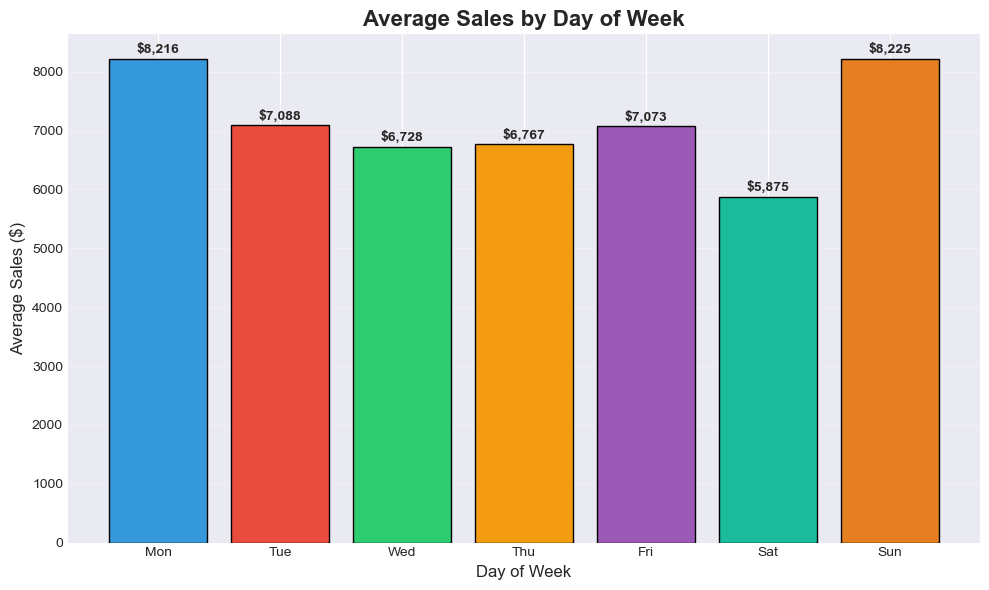

📊 Weekly Patterns:
- Best day: Day 7 with $8,225 avg sales
- Worst day: Day 6 with $5,875 avg sales
- Weekly variation: 40.0% difference


In [30]:
# Sales by Day of Week
weekly_sales = df_open.groupby('DayOfWeek')['Sales'].mean().sort_index().reset_index()

plt.figure(figsize=(10, 6))
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c', '#e67e22']
plt.bar(weekly_sales['DayOfWeek'], weekly_sales['Sales'], color=colors, edgecolor='black')
plt.title('Average Sales by Day of Week', fontsize=16, fontweight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Average Sales ($)', fontsize=12)
plt.xticks(range(1, 8), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.grid(axis='y', alpha=0.3)

# Add value labels
for i, row in weekly_sales.iterrows():
    plt.text(row['DayOfWeek'], row['Sales'] + 100, f"${row['Sales']:,.0f}", 
            ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

best_day = weekly_sales.loc[weekly_sales['Sales'].idxmax()]
worst_day = weekly_sales.loc[weekly_sales['Sales'].idxmin()]

print(f"📊 Weekly Patterns:")
print(f"- Best day: Day {int(best_day['DayOfWeek'])} with ${best_day['Sales']:,.0f} avg sales")
print(f"- Worst day: Day {int(worst_day['DayOfWeek'])} with ${worst_day['Sales']:,.0f} avg sales")
print(f"- Weekly variation: {((best_day['Sales'] / worst_day['Sales']) - 1) * 100:.1f}% difference")


PROMOTION IMPACT ANALYSIS


,Promo,Count,Mean_Sales,Median_Sales,Std_Sales
0,0,467496,5929.407603,5459.0,2629.648385
1,1,376896,8228.281239,7649.0,3175.759157


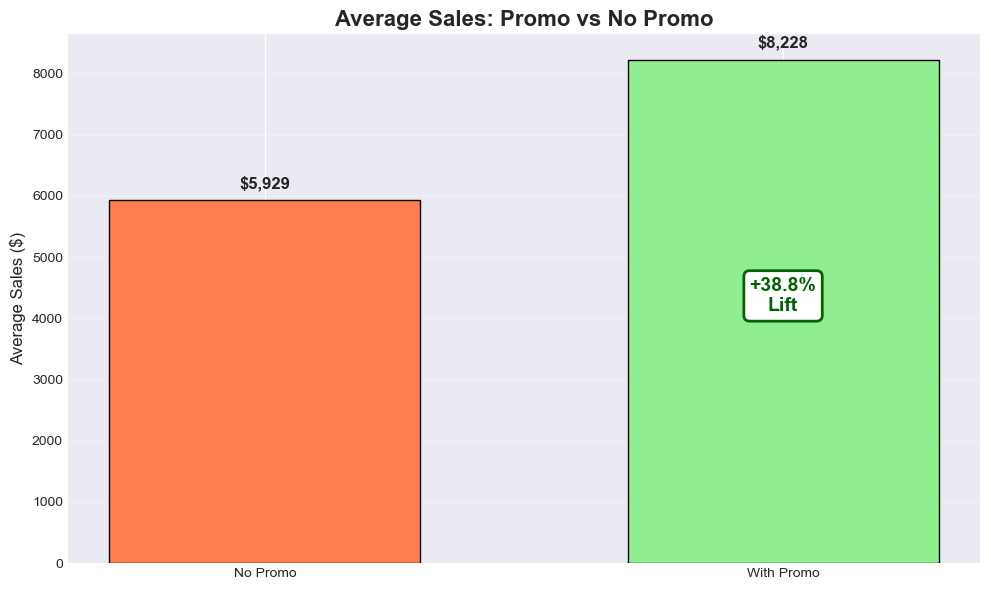


📊 Key Finding: Promotions increase sales by 38.8%


In [31]:
# Sales: Promo vs No Promo
promo_stats = df_open.groupby('Promo')['Sales'].agg(['count', 'mean', 'median', 'std']).reset_index()
promo_stats.columns = ['Promo', 'Count', 'Mean_Sales', 'Median_Sales', 'Std_Sales']

print("="*80)
print("PROMOTION IMPACT ANALYSIS")
print("="*80)
display(promo_stats)

promo_lift = ((promo_stats.loc[1, 'Mean_Sales'] / promo_stats.loc[0, 'Mean_Sales']) - 1) * 100

plt.figure(figsize=(10, 6))
bars = plt.bar(['No Promo', 'With Promo'], promo_stats['Mean_Sales'].values, 
               color=['coral', 'lightgreen'], edgecolor='black', width=0.6)
plt.title('Average Sales: Promo vs No Promo', fontsize=16, fontweight='bold')
plt.ylabel('Average Sales ($)', fontsize=12)
plt.grid(axis='y', alpha=0.3)

# Add value labels
for i, (bar, val) in enumerate(zip(bars, promo_stats['Mean_Sales'].values)):
    plt.text(bar.get_x() + bar.get_width()/2, val + 200, f'${val:,.0f}', 
            ha='center', fontsize=12, fontweight='bold')

# Add lift annotation
plt.text(1, promo_stats.loc[1, 'Mean_Sales'] / 2, f'+{promo_lift:.1f}%\nLift', 
        ha='center', fontsize=14, fontweight='bold', color='darkgreen',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='darkgreen', linewidth=2))

plt.tight_layout()
plt.show()

print(f"\n📊 Key Finding: Promotions increase sales by {promo_lift:.1f}%")

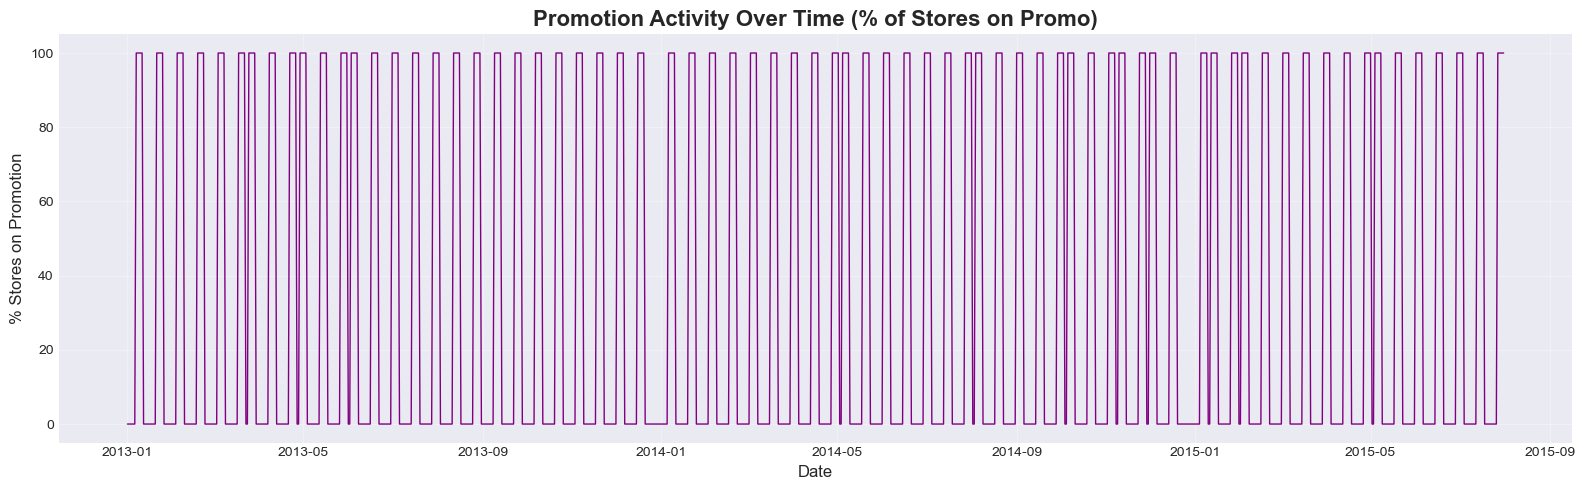

In [32]:
# Promo distribution over time
promo_over_time = df_open.groupby('Date')['Promo'].mean() * 100

plt.figure(figsize=(16, 5))
plt.plot(promo_over_time.index, promo_over_time.values, linewidth=1, color='purple')
plt.title('Promotion Activity Over Time (% of Stores on Promo)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('% Stores on Promotion', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

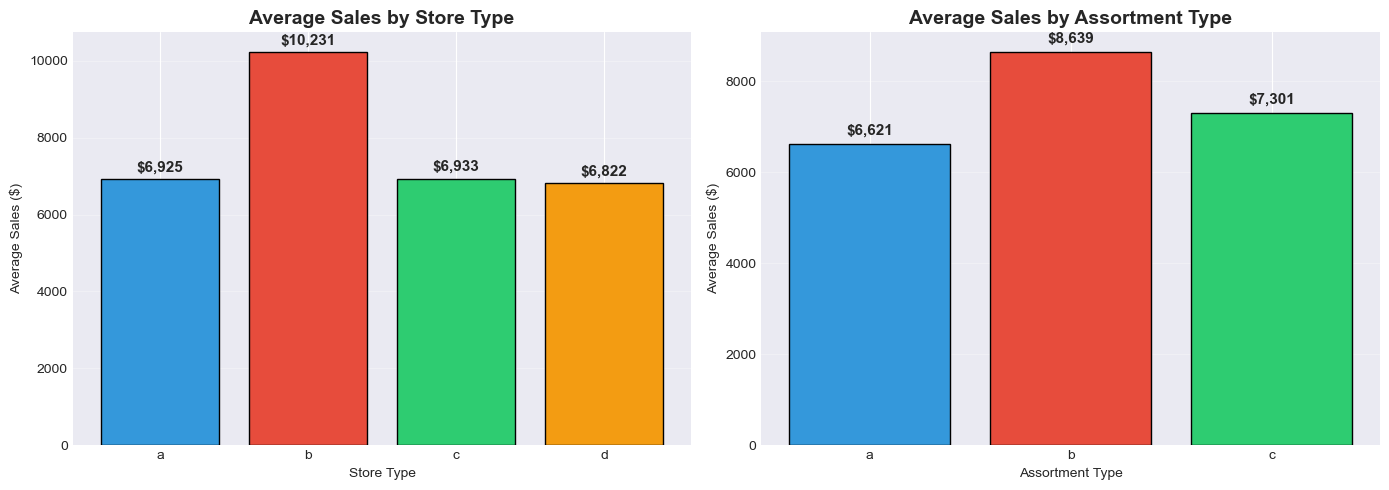

STORE TYPE STATISTICS


,StoreType,count,mean,median,std
0,a,457077,6925.167661,6285.0,3277.786381
1,b,15563,10231.407505,9130.0,5157.190155
2,c,112978,6932.512755,6407.0,2897.564578
3,d,258774,6822.141881,6395.0,2556.582881


In [33]:
# Sales by Store Type
store_type_stats = df_open.groupby('StoreType')['Sales'].agg(['count', 'mean', 'median', 'std']).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average sales by store type
axes[0].bar(store_type_stats['StoreType'], store_type_stats['mean'], color=['#3498db', '#e74c3c', '#2ecc71', '#f39c12'], edgecolor='black')
axes[0].set_title('Average Sales by Store Type', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Store Type')
axes[0].set_ylabel('Average Sales ($)')
axes[0].grid(axis='y', alpha=0.3)
for i, row in store_type_stats.iterrows():
    axes[0].text(i, row['mean'] + 200, f"${row['mean']:,.0f}", ha='center', fontsize=11, fontweight='bold')

# Sales by Assortment
assortment_stats = df_open.groupby('Assortment')['Sales'].mean().reset_index()
axes[1].bar(assortment_stats['Assortment'], assortment_stats['Sales'], color=['#3498db', '#e74c3c', '#2ecc71'], edgecolor='black')
axes[1].set_title('Average Sales by Assortment Type', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Assortment Type')
axes[1].set_ylabel('Average Sales ($)')
axes[1].grid(axis='y', alpha=0.3)
for i, row in assortment_stats.iterrows():
    axes[1].text(i, row['Sales'] + 200, f"${row['Sales']:,.0f}", ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("="*80)
print("STORE TYPE STATISTICS")
print("="*80)
display(store_type_stats)

In [34]:
# Competition distance analysis
print("="*80)
print("COMPETITION ANALYSIS")
print("="*80)
print(f"Stores with competition data: {df_open['CompetitionDistance'].notna().sum()}")
print(f"Stores without competition data: {df_open['CompetitionDistance'].isna().sum()}")
print(f"\nCompetition Distance Statistics:")
print(df_open['CompetitionDistance'].describe())

COMPETITION ANALYSIS
Stores with competition data: 842206
Stores without competition data: 2186

Competition Distance Statistics:
count    842206.000000
mean       5457.979627
std        7809.437311
min          20.000000
25%         710.000000
50%        2320.000000
75%        6890.000000
max       75860.000000
Name: CompetitionDistance, dtype: float64


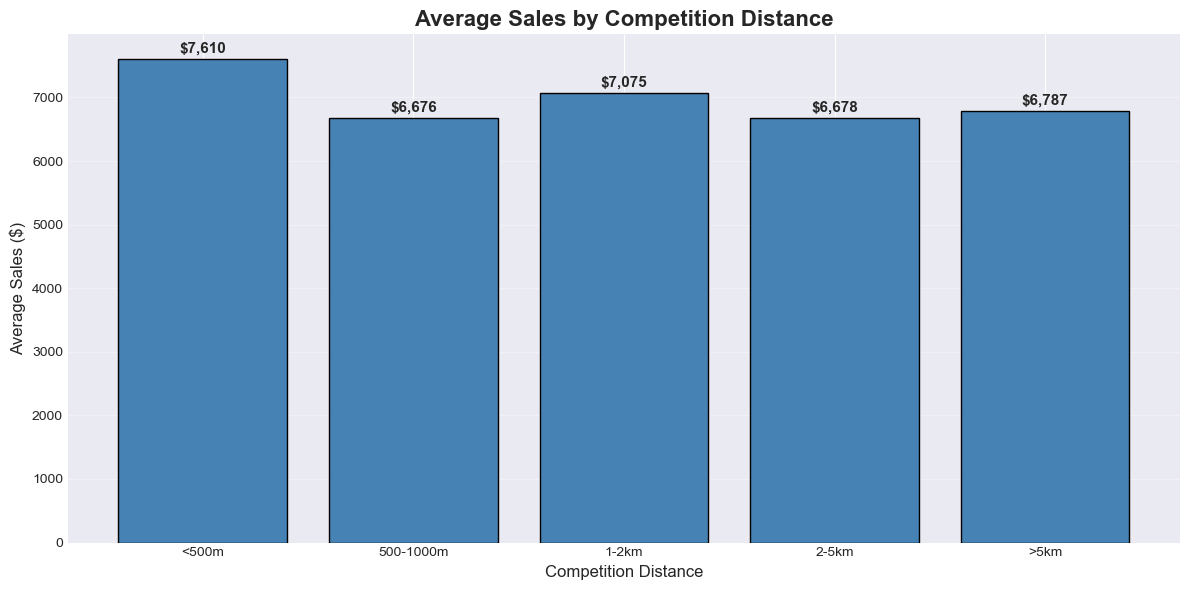

📊 Insight: Competition distance impact on sales


In [35]:
# Sales vs Competition Distance
df_comp = df_open[df_open['CompetitionDistance'].notna()].copy()
df_comp['CompetitionDistanceBin'] = pd.cut(df_comp['CompetitionDistance'], 
                                             bins=[0, 500, 1000, 2000, 5000, 100000],
                                             labels=['<500m', '500-1000m', '1-2km', '2-5km', '>5km'])

comp_sales = df_comp.groupby('CompetitionDistanceBin')['Sales'].mean().reset_index()

plt.figure(figsize=(12, 6))
plt.bar(range(len(comp_sales)), comp_sales['Sales'], color='steelblue', edgecolor='black')
plt.title('Average Sales by Competition Distance', fontsize=16, fontweight='bold')
plt.xlabel('Competition Distance', fontsize=12)
plt.ylabel('Average Sales ($)', fontsize=12)
plt.xticks(range(len(comp_sales)), comp_sales['CompetitionDistanceBin'])
plt.grid(axis='y', alpha=0.3)
for i, val in enumerate(comp_sales['Sales']):
    plt.text(i, val + 100, f'${val:,.0f}', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

print("📊 Insight: Competition distance impact on sales")

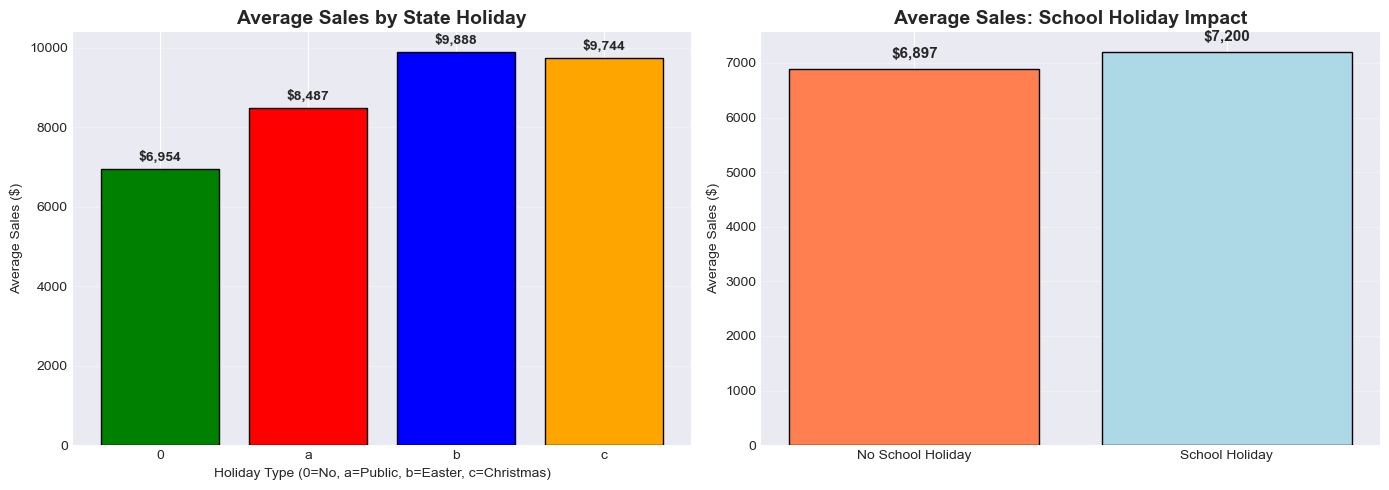

In [36]:
# Sales by State Holiday
holiday_sales = df_open.groupby('StateHoliday')['Sales'].mean().reset_index()

# Filter out '0' (no holiday) for better visualization
holiday_sales_filtered = holiday_sales[holiday_sales['StateHoliday'] != '0']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# All holidays including no-holiday
axes[0].bar(holiday_sales['StateHoliday'], holiday_sales['Sales'], color=['green', 'red', 'blue', 'orange'], edgecolor='black')
axes[0].set_title('Average Sales by State Holiday', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Holiday Type (0=No, a=Public, b=Easter, c=Christmas)')
axes[0].set_ylabel('Average Sales ($)')
axes[0].grid(axis='y', alpha=0.3)
for i, row in holiday_sales.iterrows():
    axes[0].text(i, row['Sales'] + 200, f"${row['Sales']:,.0f}", ha='center', fontsize=10, fontweight='bold')

# School holiday impact
school_holiday_sales = df_open.groupby('SchoolHoliday')['Sales'].mean().reset_index()
axes[1].bar(['No School Holiday', 'School Holiday'], school_holiday_sales['Sales'].values, 
           color=['coral', 'lightblue'], edgecolor='black')
axes[1].set_title('Average Sales: School Holiday Impact', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Average Sales ($)')
axes[1].grid(axis='y', alpha=0.3)
for i, val in enumerate(school_holiday_sales['Sales']):
    axes[1].text(i, val + 200, f'${val:,.0f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [37]:
# Focus on Store 1 for detailed analysis
store_1 = df_open[df_open['Store'] == 1].sort_values('Date').copy()

print("="*80)
print("STORE 1 ANALYSIS")
print("="*80)
print(f"Total records: {len(store_1)}")
print(f"Date range: {store_1['Date'].min().date()} to {store_1['Date'].max().date()}")
print(f"Average daily sales: ${store_1['Sales'].mean():,.2f}")
print(f"Total sales: ${store_1['Sales'].sum():,.0f}")

STORE 1 ANALYSIS
Total records: 781
Date range: 2013-01-02 to 2015-07-31
Average daily sales: $4,759.10
Total sales: $3,716,854


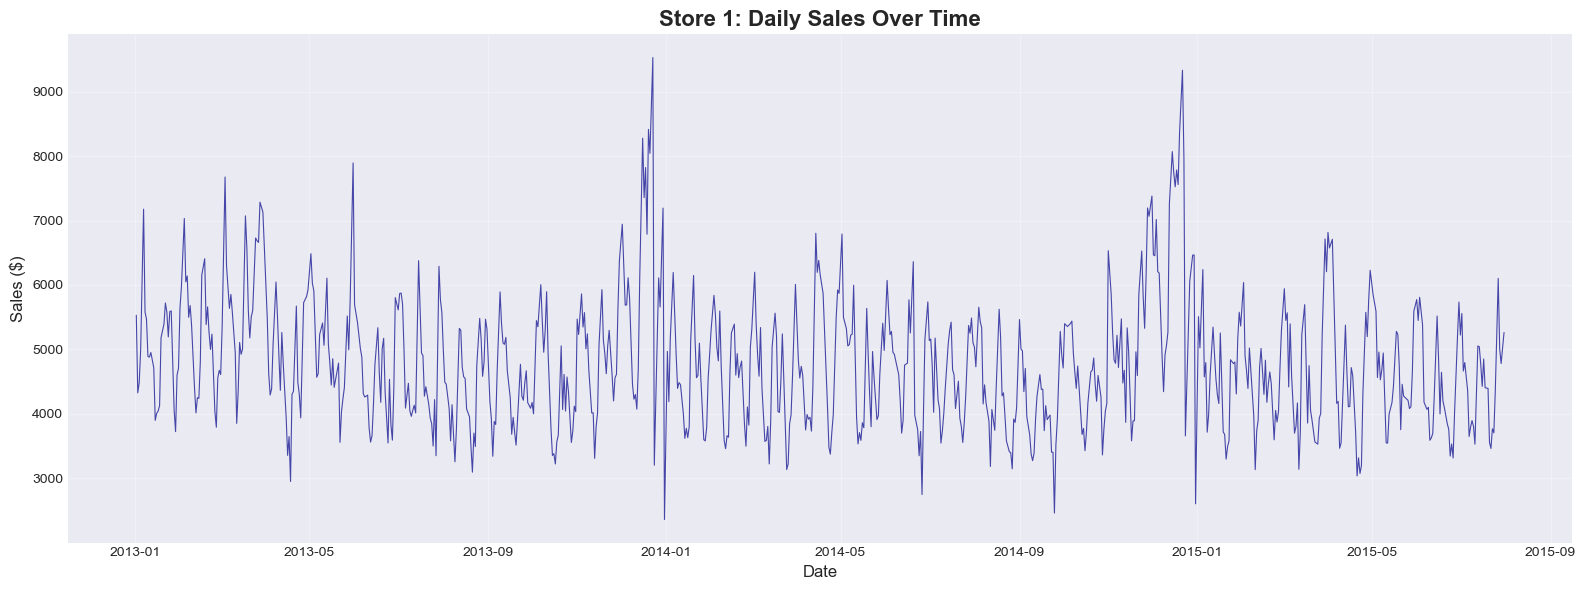

In [38]:
# Store 1 time series
plt.figure(figsize=(16, 6))
plt.plot(store_1['Date'], store_1['Sales'], linewidth=0.8, color='darkblue', alpha=0.7)
plt.title('Store 1: Daily Sales Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

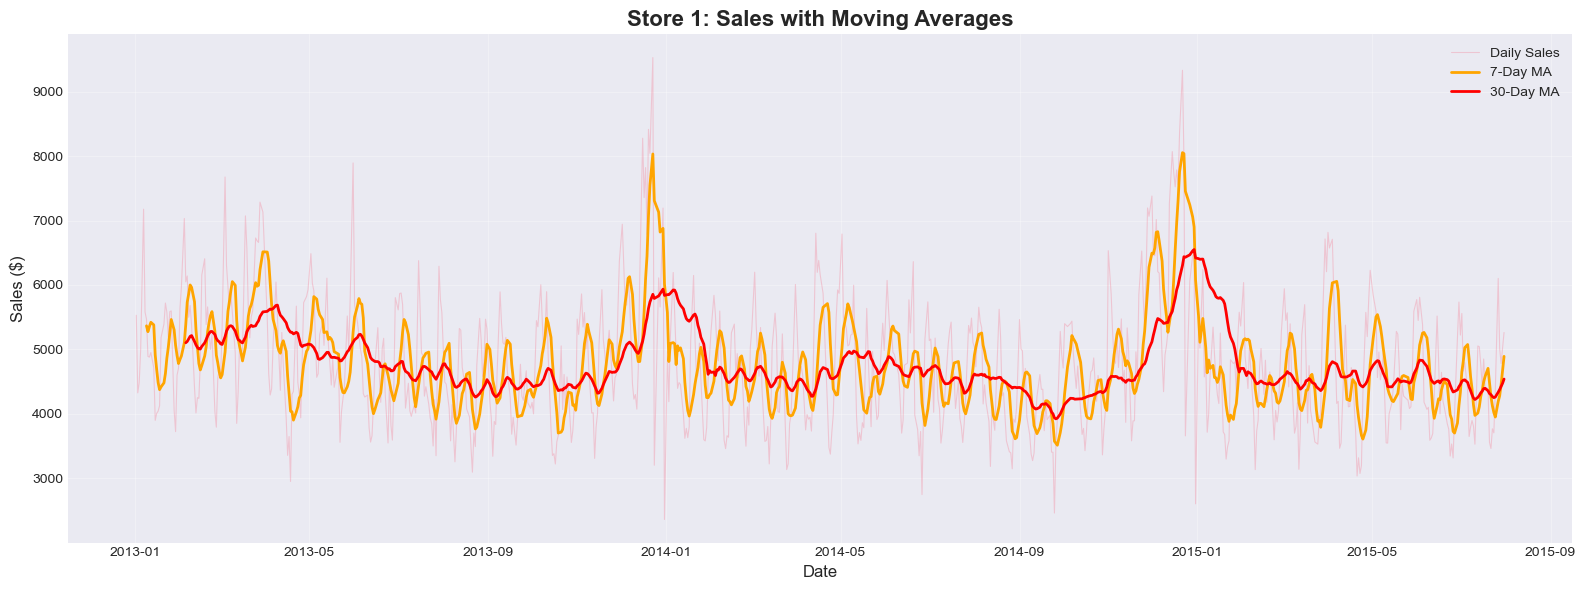

In [39]:
# Store 1 with moving averages
store_1['MA_7'] = store_1['Sales'].rolling(window=7).mean()
store_1['MA_30'] = store_1['Sales'].rolling(window=30).mean()

plt.figure(figsize=(16, 6))
plt.plot(store_1['Date'], store_1['Sales'], alpha=0.3, label='Daily Sales', linewidth=0.8)
plt.plot(store_1['Date'], store_1['MA_7'], label='7-Day MA', linewidth=2, color='orange')
plt.plot(store_1['Date'], store_1['MA_30'], label='30-Day MA', linewidth=2, color='red')
plt.title('Store 1: Sales with Moving Averages', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

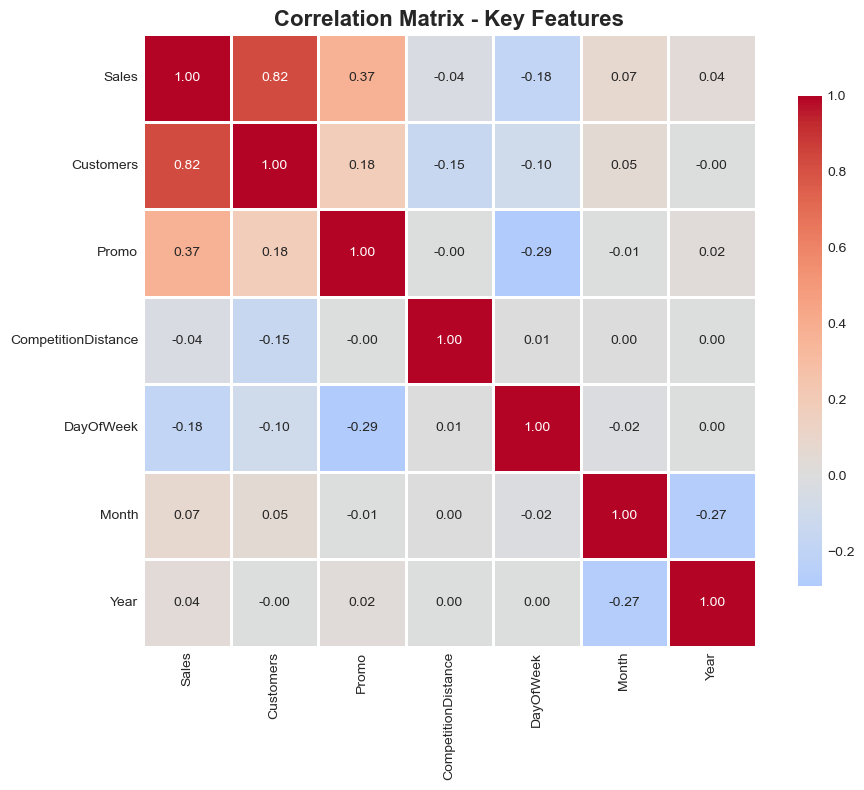

CORRELATION WITH SALES
Sales                  1.000000
Customers              0.823597
Promo                  0.368145
Month                  0.073600
Year                   0.036169
CompetitionDistance   -0.036396
DayOfWeek             -0.178736
Name: Sales, dtype: float64


In [40]:
# Select numerical features for correlation
numerical_features = ['Sales', 'Customers', 'Promo', 'CompetitionDistance', 
                      'DayOfWeek', 'Month', 'Year']

# Create correlation matrix
correlation_data = df_open[numerical_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_data, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix - Key Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("="*80)
print("CORRELATION WITH SALES")
print("="*80)
sales_corr = correlation_data['Sales'].sort_values(ascending=False)
print(sales_corr)

In [41]:
# Generate comprehensive summary
print("="*80)
print("📊 KEY FINDINGS FROM EDA")
print("="*80)

print("\n🔍 DATA OVERVIEW:")
print(f"  • Total stores: {df['Store'].nunique()}")
print(f"  • Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"  • Total records: {len(df):,}")
print(f"  • Open stores records: {len(df_open):,}")

print("\n💰 SALES INSIGHTS:")
print(f"  • Average daily sales (per store): ${df_open['Sales'].mean():,.2f}")
print(f"  • Total sales (all stores, all time): ${df_open['Sales'].sum():,.0f}")
print(f"  • Sales range: ${df_open['Sales'].min():,.0f} - ${df_open['Sales'].max():,.0f}")

print("\n📈 SEASONALITY PATTERNS:")
print(f"  • Best month: Month {monthly_sales.loc[monthly_sales['Sales'].idxmax(), 'Month']:.0f} (${monthly_sales['Sales'].max():,.0f} avg)")
print(f"  • Best day of week: Day {weekly_sales.loc[weekly_sales['Sales'].idxmax(), 'DayOfWeek']:.0f} (${weekly_sales['Sales'].max():,.0f} avg)")
print(f"  • Monthly variation: {((monthly_sales['Sales'].max() / monthly_sales['Sales'].min()) - 1) * 100:.1f}%")
print(f"  • Weekly variation: {((weekly_sales['Sales'].max() / weekly_sales['Sales'].min()) - 1) * 100:.1f}%")

print("\n🎯 PROMOTION IMPACT:")
print(f"  • Sales increase with promotion: +{promo_lift:.1f}%")
print(f"  • Days with promotion: {(df_open['Promo'].sum() / len(df_open)) * 100:.1f}%")

print("\n🏪 STORE CHARACTERISTICS:")
print(f"  • Store types: {df_open['StoreType'].nunique()} types")
print(f"  • Assortment types: {df_open['Assortment'].nunique()} types")
print(f"  • Stores with competition data: {df_open['CompetitionDistance'].notna().sum() / df_open['Store'].nunique():.1%}")

print("\n🔗 CORRELATIONS:")
print(f"  • Sales vs Customers: {correlation_data.loc['Sales', 'Customers']:.3f} (very strong)")
print(f"  • Sales vs Promo: {correlation_data.loc['Sales', 'Promo']:.3f}")
print(f"  • Sales vs DayOfWeek: {correlation_data.loc['Sales', 'DayOfWeek']:.3f}")

print("\n⚠️ DATA QUALITY:")
missing_cols = missing_store[missing_store['Missing_Count'] > 0]
if len(missing_cols) > 0:
    print(f"  • Missing values found in: {list(missing_cols.index)}")
else:
    print("  • No missing values in train data")
print(f"  • Duplicate rows: {train.duplicated().sum()}")

print("\n✅ RECOMMENDATIONS FOR MODELING:")
print("  1. Strong weekly seasonality → Use Prophet or ARIMA with seasonal components")
print("  2. Promotion is key driver → Include as feature in all models")
print("  3. Customers highly correlated with sales → Consider forecasting customers first")
print("  4. Store-specific patterns → Train separate models per store or store cluster")
print("  5. December spike → Add holiday indicators as features")
print("  6. Zero sales on closed days → Filter Open==1 for training")

📊 KEY FINDINGS FROM EDA

🔍 DATA OVERVIEW:
  • Total stores: 1115
  • Date range: 2013-01-01 to 2015-07-31
  • Total records: 1,017,209
  • Open stores records: 844,392

💰 SALES INSIGHTS:
  • Average daily sales (per store): $6,955.51
  • Total sales (all stores, all time): $5,873,180,623
  • Sales range: $0 - $41,551

📈 SEASONALITY PATTERNS:
  • Best month: Month 12 ($8,609 avg)
  • Best day of week: Day 7 ($8,225 avg)
  • Monthly variation: 31.5%
  • Weekly variation: 40.0%

🎯 PROMOTION IMPACT:
  • Sales increase with promotion: +38.8%
  • Days with promotion: 44.6%

🏪 STORE CHARACTERISTICS:
  • Store types: 4 types
  • Assortment types: 3 types
  • Stores with competition data: 75534.2%

🔗 CORRELATIONS:
  • Sales vs Customers: 0.824 (very strong)
  • Sales vs Promo: 0.368
  • Sales vs DayOfWeek: -0.179

⚠️ DATA QUALITY:
  • Missing values found in: ['PromoInterval', 'Promo2SinceYear', 'Promo2SinceWeek', 'CompetitionOpenSinceYear', 'CompetitionOpenSinceMonth', 'CompetitionDistance']
 

In [45]:
import os
os.makedirs('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed', exist_ok=True)
os.makedirs('C:/Users/Shivam Gupta/Coding/smart-supply-chain/results', exist_ok=True)
print("✅ Folders created!")

✅ Folders created!


In [49]:
# Fix date format and save
df_save = df.copy()
store_1_save = store_1.copy()

# Convert Date to proper string format
df_save['Date'] = df_save['Date'].dt.strftime('%Y-%m-%d')
store_1_save['Date'] = store_1_save['Date'].dt.strftime('%Y-%m-%d')

# Save files
df_save.to_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/train_with_features.csv', index=False)
store_1_save.to_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/store_1_data.csv', index=False)

print("✅ Files saved with correct date format!")

✅ Files saved with correct date format!


In [52]:
import json

eda_insights = {
    "dataset": {
        "total_stores": int(df['Store'].nunique()),
        "date_range": f"{df['Date'].min().date()} to {df['Date'].max().date()}",
        "total_records": int(len(df)),
        "open_store_records": int(len(df_open))
    },
    "sales": {
        "avg_daily_sales_per_store": float(df_open['Sales'].mean()),
        "total_sales": float(df_open['Sales'].sum()),
        "min_sales": float(df_open['Sales'].min()),
        "max_sales": float(df_open['Sales'].max())
    },
    "seasonality": {
        "best_month": int(monthly_sales.loc[monthly_sales['Sales'].idxmax(), 'Month']),
        "best_day_of_week": int(weekly_sales.loc[weekly_sales['Sales'].idxmax(), 'DayOfWeek']),
        "monthly_variation_pct": float(((monthly_sales['Sales'].max() / monthly_sales['Sales'].min()) - 1) * 100),
        "weekly_variation_pct": float(((weekly_sales['Sales'].max() / weekly_sales['Sales'].min()) - 1) * 100)
    },
    "promotion": {
        "sales_lift_pct": float(promo_lift),
        "days_with_promo_pct": float((df_open['Promo'].sum() / len(df_open)) * 100)
    },
    "correlations": {
        "sales_vs_customers": float(correlation_data.loc['Sales', 'Customers']),
        "sales_vs_promo": float(correlation_data.loc['Sales', 'Promo']),
        "sales_vs_day_of_week": float(correlation_data.loc['Sales', 'DayOfWeek'])
    }
}

insights_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/eda_insights.json'
with open(insights_path, 'w') as f:
    json.dump(eda_insights, f, indent=4)
print(f"✅ EDA insights saved to: {insights_path}")

✅ EDA insights saved to: C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/eda_insights.json


In [53]:
print("="*80)
print("🎉 EDA COMPLETE!")
print("="*80)
print("\n✅ Next Steps:")
print("  1. Review insights above")
print("  2. Move to Notebook 02: Data Preprocessing")
print("  3. Start building baseline models (moving average)")
print("  4. Plan ARIMA/Prophet models based on seasonality findings")
print("\n📊 Key Takeaway:")
print("  Strong weekly and monthly seasonality + promotion impact")
print("  → Perfect for time series forecasting models!")
print("="*80)

🎉 EDA COMPLETE!

✅ Next Steps:
  1. Review insights above
  2. Move to Notebook 02: Data Preprocessing
  3. Start building baseline models (moving average)
  4. Plan ARIMA/Prophet models based on seasonality findings

📊 Key Takeaway:
  Strong weekly and monthly seasonality + promotion impact
  → Perfect for time series forecasting models!
